In [1]:
# ============================
# PDE Expression Heatmap in CA
# ============================
#
# Drop this whole block into your notebook and adjust paths + region_col if needed.

import h5py
import re
import numpy as np
import pandas as pd
import scanpy as ad
from scipy.sparse import csc_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# ----------------------------
# 1) Load Allen Smart-seq data
# ----------------------------

def load_allen_smartseq_h5(path, group="data/t_exon"):
    with h5py.File(path, "r") as f:
        genes = [g.decode() for g in f["gene_names"][:]]
        cells = [s.decode() for s in f["sample_names"][:]]
        G, C = len(genes), len(cells)

        grp = f[group]
        dims = tuple(grp["dims"][:])     # e.g. (45768, 73363)
        i = grp["i"][:]
        p = grp["p"][:]
        x = grp["x"][:]

        # Build matrix as stored (CSC = columns compressed)
        X = csc_matrix((x, i, p), shape=dims)

        # Infer which axis is cells vs genes from p-length (ncols = len(p)-1)
        ncols = len(p) - 1
        if ncols == G:
            # columns are genes, rows must be cells -> OK for AnnData
            pass
        elif ncols == C:
            # columns are cells -> transpose so rows=cells, cols=genes
            X = X.T
        else:
            # Fallback: try dims against known counts
            if dims[0] == C and dims[1] == G:
                pass
            elif dims[0] == G and dims[1] == C:
                X = X.T
            else:
                raise ValueError(
                    f"Can't infer orientation: dims={dims}, genes={G}, cells={C}, ncols={ncols}"
                )

    # Now X is cells × genes
    return ad.AnnData(
        X=X,
        obs=pd.DataFrame(index=cells),   # cells
        var=pd.DataFrame(index=genes)    # genes
    )

# Load expression matrix
adata = load_allen_smartseq_h5("Data/expression_matrix.hdf5")
print(adata)  # sanity check (n_obs cells, n_vars genes)

# ----------------------------
# 2) Load and align metadata
# ----------------------------

meta = pd.read_csv("Data/metadata.csv", low_memory=False)

# Clean keys and index by sample_name
meta["sample_name"] = meta["sample_name"].astype(str).str.strip()
meta = meta.set_index("sample_name")

# Overlap report
in_meta = adata.obs_names.isin(meta.index)
print(f"Matched {in_meta.sum():,} / {adata.n_obs:,} cells "
      f"({100*in_meta.mean():.1f}%) to metadata")

# Align metadata to adata.obs_names
meta_aligned = meta.reindex(adata.obs_names)
adata.obs = adata.obs.join(meta_aligned)

# ----------------------------
# 3) Filter to pyramidal cells
# ----------------------------

pyr_subclasses = {"IT", "ET", "CT"}
has_subclass = "subclass_label" in adata.obs.columns

if has_subclass:
    mask_pyr = adata.obs["subclass_label"].astype(str).str.upper().isin(pyr_subclasses)
else:
    # Fallback: parse from cluster_label like "197_L5 IT CTX"
    pat = re.compile(r"\b(IT|ET|CT)\b", flags=re.IGNORECASE)
    mask_pyr = adata.obs["cluster_label"].astype(str).str.contains(pat)

adata_pyr = adata[mask_pyr].copy()
print("Pyramidal-only AnnData:")
print(adata_pyr)

# ----------------------------
# 4) Filter to CA (CA1/CA2/CA3)
# ----------------------------
# Adjust `region_col` depending on what your metadata has.
# Common options in Allen data: "structure_acronym", "region_label", "full_region", etc.

print("Available obs columns:", adata_pyr.obs.columns.tolist())

region_col = "structure_acronym"  # CHANGE HERE if needed



AnnData object with n_obs × n_vars = 73363 × 45768
Matched 73,347 / 73,363 cells (100.0%) to metadata
Pyramidal-only AnnData:
AnnData object with n_obs × n_vars = 0 × 45768
    obs: 'donor_sex_id', 'donor_sex_label', 'donor_sex_color', 'region_id', 'region_label', 'region_color', 'platform_label', 'cluster_order', 'cluster_label', 'cluster_color', 'subclass_order', 'subclass_label', 'subclass_color', 'neighborhood_id', 'neighborhood_label', 'neighborhood_color', 'class_order', 'class_label', 'class_color', 'exp_component_name', 'external_donor_name_label', 'full_genotype_label', 'facs_population_plan_label', 'injection_roi_label', 'injection_materials_label', 'injection_method_label', 'injection_type_label', 'full_genotype_id', 'full_genotype_color', 'external_donor_name_id', 'external_donor_name_color', 'facs_population_plan_id', 'facs_population_plan_color', 'injection_materials_id', 'injection_materials_color', 'injection_method_id', 'injection_method_color', 'injection_roi_id', 'in

KeyError: 'structure_acronym'

In [10]:
# ------------------------------------------
# Inspect region labels that contain "CA"
# ------------------------------------------

col = "region_label"

if col not in adata.obs.columns:
    raise ValueError(f"{col!r} not found in adata.obs. Available columns:\n"
                     f"{adata.obs.columns.tolist()}")

region_vals = adata.obs[col].astype(str)
display(region_vals)
# All unique region names containing "CA" (case-insensitive)
contains_ca = region_vals[region_vals.str.contains("HIP", case=False, na=False)]

print("Number of labels matching 'HIP':", contains_ca.nunique())
print("Unique matches:")
print(sorted(contains_ca.unique()))


US-1250273_E1_S37      VISp
US-1250273_E2_S01      VISp
US-1250273_E2_S02      VISp
US-1250273_E2_S03      VISp
US-1250273_E2_S04      VISp
                       ... 
SM-J39VT_S475_E1-50     SSp
SM-J39VT_S476_E1-50     SSp
SM-J39VT_S478_E1-50     SSp
SM-J39VT_S479_E1-50     SSp
SM-J39VT_S480_E1-50     SSp
Name: region_label, Length: 73363, dtype: object

Number of labels matching 'HIP': 1
Unique matches:
['HIP']


HIP excitatory subclasses AnnData:
AnnData object with n_obs × n_vars = 4404 × 45768
    obs: 'donor_sex_id', 'donor_sex_label', 'donor_sex_color', 'region_id', 'region_label', 'region_color', 'platform_label', 'cluster_order', 'cluster_label', 'cluster_color', 'subclass_order', 'subclass_label', 'subclass_color', 'neighborhood_id', 'neighborhood_label', 'neighborhood_color', 'class_order', 'class_label', 'class_color', 'exp_component_name', 'external_donor_name_label', 'full_genotype_label', 'facs_population_plan_label', 'injection_roi_label', 'injection_materials_label', 'injection_method_label', 'injection_type_label', 'full_genotype_id', 'full_genotype_color', 'external_donor_name_id', 'external_donor_name_color', 'facs_population_plan_id', 'facs_population_plan_color', 'injection_materials_id', 'injection_materials_color', 'injection_method_id', 'injection_method_color', 'injection_roi_id', 'injection_roi_color', 'injection_type_id', 'injection_type_color', 'cell_type_accession_la

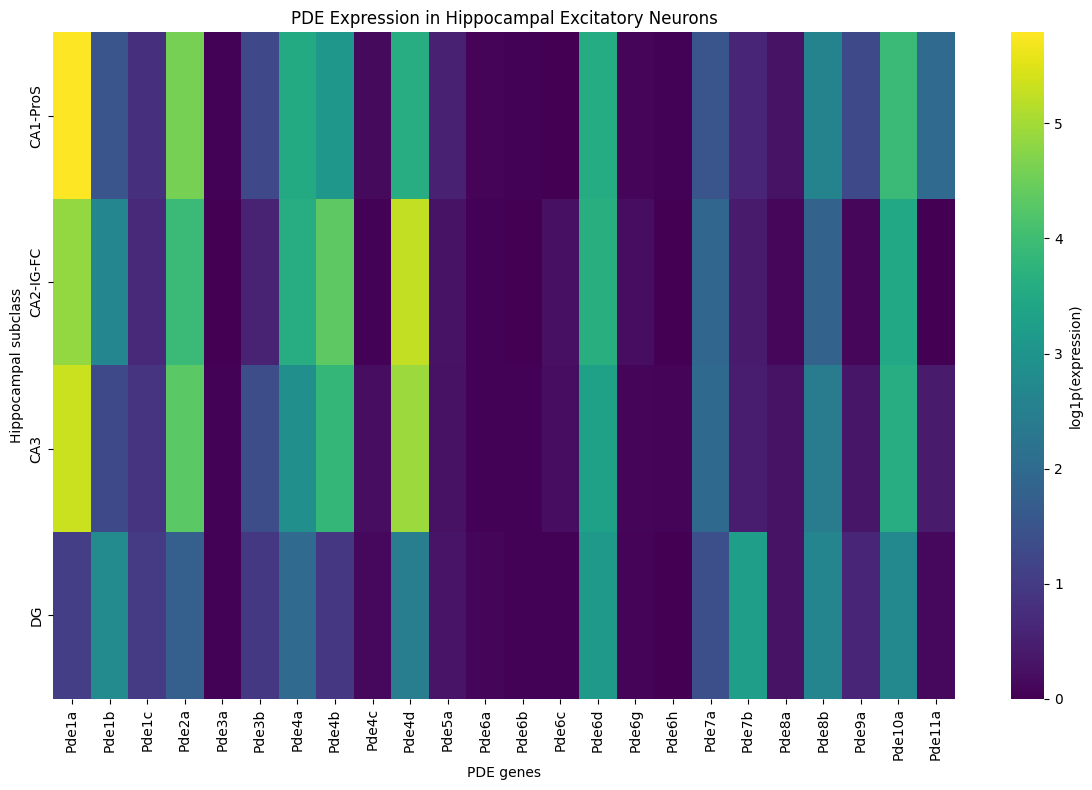

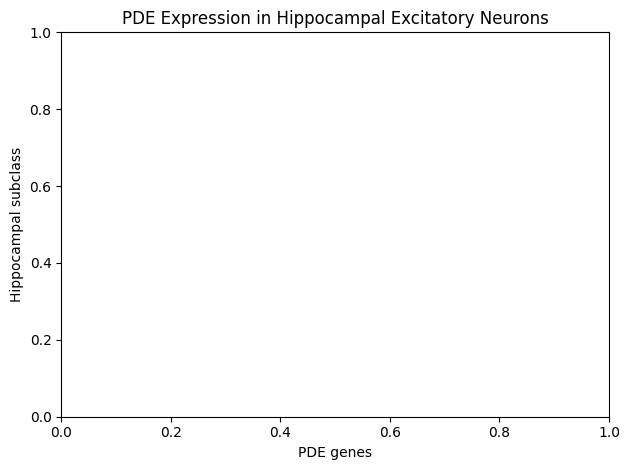

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ----------------------------
# 1) Identify hippocampal excitatory subclasses
# ----------------------------

# Patterns for HIP excitatory subclasses
hip_patterns = ["CA1", "CA2", "CA3", "DG"]

# Build mask: region must be HIP, subclass_label must match CA1/2/3/DG, and class must be Glu
region_mask = adata.obs["region_label"].astype(str) == "HIP"

subclass_series = adata.obs["subclass_label"].astype(str)
subclass_mask = subclass_series.str.contains("|".join(hip_patterns), case=False, na=False)

class_mask = adata.obs["class_label"].astype(str).str.upper() == "GLUTAMATERGIC"

mask = region_mask & subclass_mask & class_mask

adata_hip = adata[mask].copy()
print("HIP excitatory subclasses AnnData:")
print(adata_hip)
print(adata_hip.obs["subclass_label"].value_counts())


# ----------------------------
# 2) Extract PDE genes
# ----------------------------

pde_genes = [
    "PDE1A","PDE1B","PDE1C",
    "PDE2A",
    "PDE3A","PDE3B",
    "PDE4A","PDE4B","PDE4C","PDE4D",
    "PDE5A",
    "PDE6A","PDE6B","PDE6C","PDE6D","PDE6G","PDE6H",
    "PDE7A","PDE7B",
    "PDE8A","PDE8B",
    "PDE9A",
    "PDE10A",
    "PDE11A",
]

# Case-insensitive match (since your genes are like "Pde4a")
lower_to_original = {g.lower(): g for g in adata_hip.var_names}
pde_genes_use = [lower_to_original[g.lower()] for g in pde_genes if g.lower() in lower_to_original]

print("PDE genes found:", pde_genes_use)

adata_hip_pde = adata_hip[:, pde_genes_use].copy()

# ----------------------------
# 3) log1p transform
# ----------------------------

X = adata_hip_pde.X.toarray() if not isinstance(adata_hip_pde.X, np.ndarray) else adata_hip_pde.X
X_log = np.log1p(X)

# ----------------------------
# 4) Aggregate by subclass_label (CA1-ProS, CA2-IG-FC, CA3, DG)
# ----------------------------

df = pd.DataFrame(X_log, index=adata_hip_pde.obs_names, columns=adata_hip_pde.var_names)
df["subclass"] = adata_hip_pde.obs["subclass_label"].astype(str)

mean_expr = df.groupby("subclass")[pde_genes_use].mean().sort_index()
print(mean_expr)

# ----------------------------
# 5) Plot heatmap
# ----------------------------

plt.figure(figsize=(12, 2 * len(mean_expr)))
ax = sns.heatmap(
    mean_expr,
    cmap="viridis",
    xticklabels=True,
    yticklabels=True,
    cbar_kws={"label": "log1p(expression)"}   # <-- Add units here
)
plt.title("PDE Expression in Hippocampal Excitatory Neurons")
plt.xlabel("PDE genes")
plt.ylabel("Hippocampal subclass")
plt.tight_layout()
plt.show()
plt.title("PDE Expression in Hippocampal Excitatory Neurons")
plt.xlabel("PDE genes")
plt.ylabel("Hippocampal subclass")
plt.tight_layout()
plt.show()


In [ ]:
f = h5py.File('Data/expression_matrix.hdf5', 'r')
print(list(f.keys()))  # see available datasets
X = f['data']          # sparse or dense expression matrix


In [ ]:
def print_tree(name, obj):
    print(name)
f.visititems(print_tree)

In [ ]:
# read genes and cells
genes = [g.decode() for g in f["gene_names"][:]]
cells = [s.decode() for s in f["sample_names"][:]]

# choose exon or t_exon (t_exon = intron + exon)
grp = f["data/t_exon"]

shape = grp["dims"][:]
i = grp["i"][:]
p = grp["p"][:]
x = grp["x"][:]

# reconstruct sparse matrix
X = csc_matrix((x, i, p), shape=shape)
print(X.shape)


In [ ]:

def load_allen_smartseq_h5(path, group="data/t_exon"):
    with h5py.File(path, "r") as f:
        genes = [g.decode() for g in f["gene_names"][:]]
        cells = [s.decode() for s in f["sample_names"][:]]
        G, C = len(genes), len(cells)

        grp = f[group]
        dims = tuple(grp["dims"][:])     # e.g. (45768, 73363)
        i = grp["i"][:]
        p = grp["p"][:]
        x = grp["x"][:]

        # Build matrix as stored (CSC = columns compressed)
        X = csc_matrix((x, i, p), shape=dims)

        # Infer which axis is cells vs genes from p-length (ncols = len(p)-1)
        ncols = len(p) - 1
        if ncols == G:
            # columns are genes, rows must be cells -> OK for AnnData
            pass
        elif ncols == C:
            # columns are cells -> transpose so rows=cells, cols=genes
            X = X.T
        else:
            # Fallback: try dims against known counts
            if dims[0] == C and dims[1] == G:
                pass
            elif dims[0] == G and dims[1] == C:
                X = X.T
            else:
                raise ValueError(
                    f"Can't infer orientation: dims={dims}, genes={G}, cells={C}, ncols={ncols}"
                )

    # Now X is cells × genes
    return ad.AnnData(
        X=X,
        obs=pd.DataFrame(index=cells),   # cells
        var=pd.DataFrame(index=genes)    # genes
    )

# Usage
adata = load_allen_smartseq_h5("Data/expression_matrix.hdf5")
print(adata)  # should report n_obs == len(cells), n_vars == len(genes)



# 1) Load metadata (suppress dtype warning)
meta = pd.read_csv("Data/metadata.csv", low_memory=False)

# 2) Clean keys and index by sample_name
meta["sample_name"] = meta["sample_name"].astype(str).str.strip()
meta = meta.set_index("sample_name")

# 3) Report overlap so you know coverage
in_meta = adata.obs_names.isin(meta.index)
print(f"Matched {in_meta.sum():,} / {adata.n_obs:,} cells "
      f"({100*in_meta.mean():.1f}%) to metadata")

# 4) Safe join: reindex to adata.obs_names (no KeyError; missing → NaN)
meta_aligned = meta.reindex(adata.obs_names)
adata.obs = adata.obs.join(meta_aligned)

# 5) Filter to pyramidal cells
# Prefer subclass_label (IT/ET/CT). Fallback to cluster_label regex if needed.

pyr_subclasses = {"IT", "ET", "CT"}
has_subclass = "subclass_label" in adata.obs.columns

if has_subclass:
    mask_pyr = adata.obs["subclass_label"].astype(str).str.upper().isin(pyr_subclasses)
else:
    # Fallback: parse from cluster_label like "197_L5 IT CTX"
    pat = re.compile(r"\b(IT|ET|CT)\b", flags=re.IGNORECASE)
    mask_pyr = adata.obs["cluster_label"].astype(str).str.contains(pat)

adata_pyr = adata[mask_pyr].copy()
print(adata_pyr)



In [ ]:
pde_genes = [
    "PDE1A", "PDE1B", "PDE1C",
    "PDE2A",
    "PDE3A", "PDE3B",
    "PDE4A", "PDE4B", "PDE4C", "PDE4D",
    "PDE5A",
    "PDE6A", "PDE6B", "PDE6C", "PDE6D", "PDE6G", "PDE6H",
    "PDE7A", "PDE7B",
    "PDE8A", "PDE8B",
    "PDE9A",
    "PDE10A",
    "PDE11A",
]

# Case + presence check
var_genes = pd.Index(adata_pyr.var_names)
pde_present = sorted(var_genes.intersection(pde_genes))

print(f"{len(pde_present)} PDE genes found in matrix:")
print(pde_present)


In [ ]:
# Optional: try case-insensitive mapping
lower_to_original = {g.lower(): g for g in var_genes}
pde_present_ci = sorted(
    {lower_to_original[g.lower()] for g in pde_genes if g.lower() in lower_to_original}
)
print("Case-insensitive matches:", pde_present_ci)


In [ ]:
# Quick sanity check of labels
print(adata.obs["class_label"].value_counts().head())
print(adata.obs["subclass_label"].value_counts().head(20))

In [ ]:
adata_pyr = adata[adata.obs["class_label"].str.contains("Glutamatergic", case=False, na=False)].copy()
print(adata_pyr)
keep = {"IT", "PT", "CT"}        # add "NP" if you want near-projecting excitatory too
sub = adata.obs["subclass_label"].astype(str).str.upper()
adata_pyr = adata[sub.isin(keep)].copy()
print(adata_pyr)


In [ ]:
pat = re.compile(r"\b(IT|PT|CT|ET|NP)\b", re.IGNORECASE)
mask = adata.obs["cluster_label"].astype(str).str.contains(pat)
adata_pyr = adata[mask].copy()


In [ ]:
adata_pyr = adata[adata.obs["class_label"].str.contains("Glutamatergic", case=False, na=False)].copy()
print(adata_pyr.n_obs, "pyramidal (all regions)")


In [ ]:
adata_pt = adata[adata.obs["subclass_label"].eq("L5 PT CTX")].copy()
print(adata_pt.n_obs, "layer-5 PT (ET-type) cells")

In [ ]:
genes_of_interest = [
    "Fos","Fosb","Junb","Egr1","Egr2","Npas4","Arc","Homer1a",
    "Nr4a1","Nr4a2","Bdnf","Nptx2","Syt4","Camk2g",
    "Rgs4","Dusp1","Atf3","Crem","Gadd45b","Gadd45g","Prkcz"
]


found = [g for g in genes_of_interest if g in adata.var_names]
expr = adata[:, found].X.toarray()
expr_z = (expr - expr.mean(axis=0)) / expr.std(axis=0)
adata.obs["plasticity_score"] = expr_z.mean(axis=1)

In [ ]:
expr_z

In [ ]:
import numpy as np
from scipy.sparse import issparse

found = [g for g in genes_of_interest if g in adata.var_names]
if not found:
    raise ValueError("None of the target genes are in adata.var_names")

X = adata[:, found].X
X = X.toarray() if issparse(X) else np.asarray(X)

# Z-score each gene across cells
expr_z = (X - X.mean(axis=0)) / (X.std(axis=0) + 1e-8)

# Per-cell plasticity score = mean z across genes
adata.obs["plasticity_score"] = expr_z.mean(axis=1)

print("genes found:", found)
print("Plasticity score range:", adata.obs["plasticity_score"].min(), adata.obs["plasticity_score"].max())


In [ ]:
adata.obs["plasticity_score_scaled"] = (
    adata.obs.groupby("subclass_label")["plasticity_score"]
    .transform(lambda x: (x - x.mean()) / (x.std() + 1e-8))
)

import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))
sns.violinplot(data=adata.obs, x="subclass_label", y="plasticity_score_scaled", cut=0)

plt.xticks(rotation=90)
plt.show()

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt


In [ ]:
avg = (
    adata.obs.groupby("subclass_label")["plasticity_score"]
    .mean()
    .sort_values(ascending=False)
)
print(avg.head(10))

plt.figure(figsize=(15, 3))
sns.heatmap(avg.to_frame().T, cmap="magma", cbar_kws={"label": "Mean plasticity"})
plt.yticks([])
plt.xlabel("Subclass")
plt.title("Mean plasticity score by subclass")
plt.show()


In [ ]:
order = ["L2/3 IT CTX","L4/5 IT CTX","L5 IT CTX","L5 PT CTX","L6 IT CTX","L6 CT CTX"]
sns.boxplot(data=adata.obs, x="subclass_label", y="plasticity_score",
            order=order, color="gray")
plt.xticks(rotation=45)
plt.show()


In [ ]:
stats = (
    adata.obs
    .groupby("subclass_label")["plasticity_score"]
    .agg(["mean", "std", "count"])
    .sort_values("mean", ascending=False)
)
print(stats.head(10))
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 3))
sns.heatmap(
    stats[["std"]].T,          # one row (std) across subclasses
    cmap="mako",               # good for continuous low–high
    cbar_kws={"label": "Plasticity score SD"}
)
plt.title("Within-subclass variability of plasticity score")
plt.xlabel("Subclass")
plt.ylabel("Std")
plt.xticks(rotation=45, ha="right")
plt.show()


In [ ]:
import numpy as np
stats["cv"] = stats["std"] / (stats["mean"].replace(0, np.nan))

plt.figure(figsize=(15,3))
sns.heatmap(
    stats[["cv"]].T,
    cmap="viridis",
    cbar_kws={"label": "Coefficient of variation (std / mean)"}
)
plt.title("Relative heterogeneity of plasticity score per subclass")
plt.xlabel("Subclass")
plt.xticks(rotation=45, ha="right")
plt.show()


In [ ]:
adata_l5 = adata[adata.obs["subclass_label"].isin(["L5 IT CTX","L5 PT CTX"]), :].copy()


In [ ]:
import scanpy as sc
import numpy as np

# --- L5 only (if you haven't already) ---
# adata_l5 = adata[adata.obs["subclass_label"].isin(["L5 IT CTX","L5 PT CTX"])].copy()

# pick plasticity genes present
genes_plastic = ["Fos","Fosb","Junb","Egr1","Egr2","Npas4","Arc","Nr4a1","Nr4a2",
                 "Bdnf","Nptx2","Syt4","Camk2g","Rgs4","Dusp1","Atf3","Crem",
                 "Gadd45b","Gadd45g","Prkcz"]
genes_plastic = [g for g in genes_plastic if g in adata_l5.var_names]

adata_l5_pl = adata_l5[:, genes_plastic].copy()

# basic preprocessing
sc.pp.normalize_total(adata_l5_pl, target_sum=1e4)
sc.pp.log1p(adata_l5_pl)

# avoid densifying if you want (optional); with 20 genes either is fine
sc.pp.scale(adata_l5_pl, zero_center=False)

# PCA: use fewer components than #genes
n_pc = max(2, min(10, len(genes_plastic)-1))
sc.tl.pca(adata_l5_pl, n_comps=n_pc, svd_solver="auto")

# neighbors/UMAP
sc.pp.neighbors(adata_l5_pl, n_neighbors=15, n_pcs=n_pc)
sc.tl.umap(adata_l5_pl)

# visualize
sc.pl.umap(adata_l5_pl, color=["subclass_label", "plasticity_score"], cmap="magma")


In [ ]:
from scipy.stats import spearmanr

# Correlation between UMAP1/UMAP2 and plasticity_score
for axis in ["X_umap1", "X_umap2"]:
    corr, p = spearmanr(adata_l5_pl.obsm["X_umap"][:,0], adata_l5_pl.obs["plasticity_score"])
    print(f"Correlation {axis}: {corr:.3f}, p={p:.1e}")


In [ ]:
# cluster
sc.tl.leiden(adata_l5_pl, resolution=0.4)
sc.pl.umap(adata_l5_pl, color=["leiden","plasticity_score","subclass_label"])

# do clusters track plasticity?
cluster_mean = adata_l5_pl.obs.groupby("leiden")["plasticity_score"].mean().sort_values()
print(cluster_mean)


In [ ]:
for grp in ["L5 IT CTX","L5 PT CTX"]:
    ad = adata_l5[adata_l5.obs["subclass_label"].eq(grp)].copy()
    qh, ql = ad.obs["plasticity_score"].quantile([0.9, 0.1])
    ad.obs["plast_group"] = np.where(ad.obs["plasticity_score"]>=qh,"high",
                             np.where(ad.obs["plasticity_score"]<=ql,"low","mid"))
    sc.tl.rank_genes_groups(ad, "plast_group", groups=["high"], reference="low", method="wilcoxon")
    sc.pl.rank_genes_groups(ad, n_genes=20, sharey=False, title=grp)


In [ ]:
sc.pl.umap(adata_l5_pl, color=["region_label","cortical_layer_label"])



In [ ]:
import numpy as np
for subclass in ["L5 IT CTX","L5 PT CTX"]:
    ad = adata_l5_pl[adata_l5_pl.obs["subclass_label"] == subclass].copy()
    qh, ql = ad.obs["plasticity_score"].quantile([0.9, 0.1])
    ad.obs["state"] = np.where(ad.obs["plasticity_score"]>=qh,"high",
                       np.where(ad.obs["plasticity_score"]<=ql,"low","mid"))
    sc.tl.rank_genes_groups(ad, "state", groups=["high"], reference="low", method="wilcoxon")
    sc.pl.rank_genes_groups(ad, n_genes=15, sharey=False, title=subclass)


In [ ]:
import scanpy as sc

adata_l5_all = adata_l5.copy()

sc.pp.normalize_total(adata_l5_all, target_sum=1e4)
sc.pp.log1p(adata_l5_all)
sc.pp.highly_variable_genes(adata_l5_all, n_top_genes=2000, flavor="seurat")
adata_l5_all = adata_l5_all[:, adata_l5_all.var["highly_variable"]].copy()
sc.pp.scale(adata_l5_all, max_value=10)
sc.tl.pca(adata_l5_all, n_comps=50)
sc.pp.neighbors(adata_l5_all, n_neighbors=15, n_pcs=30)
sc.tl.umap(adata_l5_all)

sc.pl.umap(adata_l5_all, color=["subclass_label", "plasticity_score"], cmap="magma")


In [ ]:
from scipy.sparse import issparse
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# After you've done HVG subsetting:
# adata_l5_all = adata_l5_all[:, adata_l5_all.var["highly_variable"]].copy()

# Dense arrays
def dense(X):
    return X.toarray() if issparse(X) else X

X_all = dense(adata_l5_all.X)  # shape: n_cells × 2000 (HVGs)

# Fit PCA on all-genes (HVG) space
pca_all = PCA(n_components=10, random_state=0).fit(X_all)

# Use the *same cells* and *same 2000 HVGs* for the "projection" matrix
# (these are the cells in your plasticity subset)
cells = adata_l5_pl.obs_names
X_pl_hvg = dense(adata_l5_all[cells, :].X)  # same 2000 features!

proj = pca_all.transform(X_pl_hvg)

plt.figure(figsize=(5,4))
scat = plt.scatter(proj[:,0], proj[:,1],
                   c=adata_l5_pl.obs["plasticity_score"].values, s=2, alpha=0.75)
plt.xlabel("PC1 (HVG PCA)"); plt.ylabel("PC2 (HVG PCA)")
plt.colorbar(scat, label="plasticity_score")
plt.title("L5 cells in all-gene PCA space colored by plasticity")
plt.tight_layout(); plt.show()


In [ ]:
import statsmodels.api as sm
import pandas as pd

df = adata_l5_all.obs[["plasticity_score","subclass_label"]].copy()
df = pd.get_dummies(df, drop_first=True)  # encode subclass
X = sm.add_constant(df[["subclass_label_L5 PT CTX"]])
y = adata_l5_all.obs["plasticity_score"]
model = sm.OLS(y, X).fit()
print(model.summary())


In [ ]:
import scanpy as sc
import numpy as np

# work on the all-genes L5 object you already normalized/logged
ad = adata_l5_all.copy()

# define high/low states within L5
qh, ql = ad.obs["plasticity_score"].quantile([0.9, 0.1])
ad.obs["plast_group"] = np.where(ad.obs["plasticity_score"]>=qh,"high",
                         np.where(ad.obs["plasticity_score"]<=ql,"low","mid"))

# run DE (high vs low)
sc.tl.rank_genes_groups(ad, groupby="plast_group", groups=["high"], reference="low", method="wilcoxon")
sc.pl.rank_genes_groups(ad, n_genes=20, sharey=False)


In [ ]:
from sklearn.decomposition import PCA

for s in ["L5 IT CTX","L5 PT CTX"]:
    sub = adata_l5_all[adata_l5_all.obs["subclass_label"]==s, genes_plastic].X.toarray()
    pc1 = PCA(n_components=1).fit_transform(sub)
    adata_l5_all.obs.loc[adata_l5_all.obs["subclass_label"]==s,"plasticity_PC1"] = pc1.ravel()


In [ ]:
from scipy.stats import spearmanr
corrs = []
for g in adata_l5_all.var_names:
    r,_ = spearmanr(adata_l5_all[:,g].X.toarray().ravel(),
                    adata_l5_all.obs["plasticity_score"])
    corrs.append(r)


In [ ]:
from scipy.stats import spearmanr
import pandas as pd

expr = adata_l5_all.X if not issparse(adata_l5_all.X) else adata_l5_all.X.toarray()
scores = adata_l5_all.obs["plasticity_score"].values
r = []
for i, g in enumerate(adata_l5_all.var_names):
    rho, p = spearmanr(expr[:, i], scores)
    r.append((g, rho, p))
corr_df = pd.DataFrame(r, columns=["gene","rho","p"]).sort_values("rho", ascending=False)
corr_df.head(20)  # top co-varying genes


In [ ]:
import statsmodels.api as sm
df = adata_l5_all.obs[["plasticity_score","subclass_label","region_label"]].copy()
df = pd.get_dummies(df, drop_first=True)
X = sm.add_constant(df.drop(columns="plasticity_score"))
y = df["plasticity_score"]
print(sm.OLS(y, X).fit().summary())


In [ ]:
sc.pl.umap(adata_l5_all, color=["Fos","Arc","Bdnf","Nr4a1"], cmap="magma")

In [ ]:
import pingouin as pg
import pandas as pd
from scipy.sparse import issparse

# Build a clean DataFrame
fos = adata_l5_all[:, "Fos"].X
fos = fos.toarray().ravel() if issparse(fos) else fos.ravel()

df = pd.DataFrame({
    "plasticity_score": adata_l5_all.obs["plasticity_score"].values,
    "Fos": fos,
    "region": adata_l5_all.obs["region_label"].astype("category").cat.codes,
    "subclass": adata_l5_all.obs["subclass_label"].astype("category").cat.codes,
})

# Option A: spearman (works now that covariates are numeric)
pg.partial_corr(data=df, x="Fos", y="plasticity_score",
                covar=["region","subclass"], method="spearman")




In [ ]:
import numpy as np, pandas as pd
from scipy.sparse import issparse
from scipy.stats import spearmanr
from sklearn.linear_model import LinearRegression

# --- Base DF with numeric covariates ---
base = pd.DataFrame({
    "plasticity_score": adata_l5_all.obs["plasticity_score"].values,
    "region": adata_l5_all.obs["region_label"].astype("category").cat.codes,
    "subclass": adata_l5_all.obs["subclass_label"].astype("category").cat.codes,
})
cov = base[["region","subclass"]].values

# Rank-transform for Spearman (monotone-invariant)
rank = base.copy()
rank["plasticity_score"] = rank["plasticity_score"].rank(method="average")

# Residualize plasticity wrt covariates
lr = LinearRegression()
lr.fit(cov, rank["plasticity_score"].values)
plast_resid = rank["plasticity_score"].values - lr.predict(cov)

def expr_dense(g):
    Xg = adata_l5_all[:, g].X
    return Xg.toarray().ravel() if issparse(Xg) else Xg.ravel()

genes_to_test = ["Fos","Arc","Bdnf","Nr4a1","Homer1","Dusp1","Nptx2","Egr1","Egr2","Egr3"]

rows = []
for g in genes_to_test:
    x = expr_dense(g)
    # rank, residualize, and drop NaNs per-gene
    valid = np.isfinite(x)
    x_rank = pd.Series(x[valid]).rank(method="average").values
    lr.fit(cov[valid], x_rank)
    x_resid = x_rank - lr.predict(cov[valid])
    r, p = spearmanr(x_resid, plast_resid[valid])
    rows.append({"gene": g, "r_partial": r, "p_partial": p, "n": int(valid.sum())})

pcorr_df = pd.DataFrame(rows).sort_values("r_partial", ascending=False)
pcorr_df


In [ ]:
region_mean = adata_l5_all.obs.groupby("region_label")["plasticity_score"].mean().sort_values()
sns.barplot(y=region_mean.index, x=region_mean.values)


In [ ]:
# assuming corr_df is your gene/rho/p table
top_genes = corr_df.head(100)["gene"].tolist()   # top 100 correlated genes

# top_genes already defined, e.g. corr_df.head(100)["gene"].tolist()
from gprofiler import GProfiler
gp = GProfiler(return_dataframe=True)

gp_results = gp.profile(organism="mmusculus", query=top_genes)

# Inspect available columns
print(gp_results.columns.tolist())

# Nice compact view
out = (gp_results
       .sort_values("p_value")
       .loc[:, ["name","source","p_value","term_size","query_size","intersection_size"]]
       .head(15))
out



In [ ]:
top_genes

In [ ]:
import numpy as np, pandas as pd
from scipy.sparse import issparse
from scipy.stats import spearmanr
from sklearn.linear_model import LinearRegression
from statsmodels.stats.multitest import multipletests

# numeric covariates
cov = pd.DataFrame({
    "region":   adata_l5_all.obs["region_label"].astype("category").cat.codes,
    "subclass": adata_l5_all.obs["subclass_label"].astype("category").cat.codes,
})
y = adata_l5_all.obs["plasticity_score"].values

# rank + residualize plasticity
y_rank = pd.Series(y).rank(method="average").values
lr = LinearRegression().fit(cov.values, y_rank)
y_resid = y_rank - lr.predict(cov.values)

def expr_vec(g):
    Xg = adata_l5_all[:, g].X
    return (Xg.toarray().ravel() if issparse(Xg) else np.asarray(Xg).ravel())

rows = []
for g in adata_l5_all.var_names:
    x = expr_vec(g)
    valid = np.isfinite(x)
    if valid.sum() < 3 or np.all(x[valid]==x[valid][0]):  # constant/too few
        continue
    x_rank = pd.Series(x[valid]).rank(method="average").values
    lr.fit(cov.values[valid], x_rank)
    x_resid = x_rank - lr.predict(cov.values[valid])
    r, p = spearmanr(x_resid, y_resid[valid])
    rows.append((g, r, p, int(valid.sum())))

pcorr = pd.DataFrame(rows, columns=["gene","r_partial","p_partial","n"])
pcorr["q_partial"] = multipletests(pcorr["p_partial"], method="fdr_bh")[1]
pcorr = pcorr.sort_values("q_partial")
pcorr.to_csv("plasticity_partial_corr_L5_allgenes.csv", index=False)
pcorr.head(20)


In [ ]:
# choose top 100 by partial correlation
top_plastic = pcorr.sort_values("r_partial", ascending=False).head(100)["gene"].tolist()

# score per cell (Scanpy’s built-in module score)
import scanpy as sc
sc.tl.score_genes(adata_l5_all, gene_list=top_plastic, score_name="plasticity_module_score")

# sanity: correlate with your original plasticity_score
from scipy.stats import spearmanr
rho, p = spearmanr(adata_l5_all.obs["plasticity_score"], adata_l5_all.obs["plasticity_module_score"])
print("module vs original:", rho, p)

# visualize
sc.pl.umap(adata_l5_all, color=["plasticity_module_score","plasticity_score"], cmap="magma")


In [ ]:
from gprofiler import GProfiler
gp = GProfiler(return_dataframe=True)
top_genes = pcorr.sort_values("r_partial", ascending=False).head(150)["gene"].tolist()

gp_results = gp.profile(
    organism="mmusculus",
    query=top_genes,
    sources=["GO:BP","REAC","KEGG"],
    user_threshold=0.05,
    all_results=True,
    ordered=True
).sort_values("p_value")

cols = ["name","source","p_value","term_size","query_size","intersection_size"]
print(gp_results[cols].head(20))
gp_results.to_csv("enrichment_plasticity_top150.csv", index=False)

# optional: filter for nervous-system/synaptic keywords
focus = gp_results[gp_results["name"].str.contains(
    "synap|plastic|memory|LTP|MAPK|ERK|cAMP|CREB|neurotroph|glutamat|GABA",
    case=False)]
focus[cols].head(20)


In [ ]:
# regress out region from plasticity_score to show within-region variability
from sklearn.linear_model import LinearRegression
reg_codes = adata_l5_all.obs["region_label"].astype("category").cat.codes.values
X = pd.get_dummies(reg_codes).values  # one-hot region
adj = LinearRegression().fit(X, y).resid if hasattr(LinearRegression(), "resid") else y - LinearRegression().fit(X, y).predict(X)
adata_l5_all.obs["plasticity_score_adjRegion"] = adj

sc.pl.umap(adata_l5_all, color="plasticity_score_adjRegion", cmap="magma")


In [ ]:
import seaborn as sns, numpy as np
g = (adata_l5_all.obs.groupby("region_label")["plasticity_score"]
     .agg(["mean","count","std"]).sort_values("mean"))
g["sem"] = g["std"]/np.sqrt(g["count"])
sns.barplot(y=g.index, x=g["mean"], xerr=g["sem"], color="tab:purple")


In [ ]:
import scanpy as sc
sc.tl.dendrogram(adata_l5_all, groupby="region_label", use_rep="X_pca")
